## Water Levels at Banagher Bridge, River Shannon, Station 25017

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from datetime import datetime
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV

import warnings
warnings.filterwarnings('ignore')

colour_pal = sns.color_palette('Paired')
#plt.style.use('fivethirtyeight') # - I am not sure I like this


In [4]:
# declare some constants
# https://www.youtube.com/watch?v=vV12dGe_Fho&t=132s

## correct for height above malin head
height = 30.330 # this is height of sensor 25017 above Malin Head
#df['DayMin'] = df['DayMin'] - height
'''
I want to calculate the floodline here, 
## Suggest last thursday is 3 feet above flood. - Dec 2023, check data for exact date! 17th?

Find scalar for flood level in M. I suggest 3m less one foot, 0.3048m

also import mean and percentile values from the waterlevels website, and compare them.
'''

field_flood = 3 - 0.3048 # in m - last estimate April 14th 2024 1ft water in field

print(field_flood)

2.6952


In [21]:
#importing the datasets

# https://waterlevel.ie/hydro-data/#/overview/Waterlevel/station/11617/Banagher/Qdownload

# this dataset has the hourly readouts.
df = pd.read_csv('tsvalues.csv', sep=';', skiprows=10).iloc[:, :-1] # drop the water quality for now
df['Timestamp'] = df['#Timestamp']

df = df.set_index('Timestamp') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)
df['Value'] = df['Value'] - height # to recalibrate water level, keep colname value for now.

# this dataset has one datapoint for each day. # dataset 2
df_daily = pd.read_csv('25017_banagher_s_complete.csv', skiprows=12).iloc[:, :-1] # for now exclude the quality column

df_daily = df_daily.set_index('Day') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df_daily.index = pd.to_datetime(df_daily.index, format='mixed', dayfirst=True)

# to recalibrate water levels # can do this in one line.
df_daily['Day Min'] = df_daily['Day Min'] - height 
df_daily['Day Mean'] = df_daily['Day Mean'] - height 
df_daily['Day Max'] = df_daily['Day Max'] - height 

NUMERICAL_FEATURES = df.select_dtypes(include=['int64', 'float64']).columns

print(NUMERICAL_FEATURES)

%whos DataFrame
df_daily.info()

Index(['Value'], dtype='object')
Variable       Type         Data/Info
-------------------------------------
df             DataFrame                             <...>1218710 rows x 2 columns]
df2            DataFrame                Day Min  Day <...>n[12855 rows x 3 columns]
df_daily       DataFrame                Day Min  Day <...>n[12855 rows x 3 columns]
df_one_point   DataFrame                             <...>n[25390 rows x 2 columns]
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12855 entries, 1989-01-02 to 2024-03-13
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Day Min   12855 non-null  float64
 1   Day Mean  12855 non-null  float64
 2   Day Max   12855 non-null  float64
dtypes: float64(3)
memory usage: 401.7 KB


In [20]:
#df.head()
#df.tail()
#df.index
df_daily.describe()  # there are issues in outliers here every now and then from the sensor which must be dropped

,Day Min,Day Mean,Day Max
count,12855.000000,12855.000000,12855.000000
mean,2.208290,2.224877,2.246209
std,3.239626,3.254717,3.244320
min,-30.330000,-30.330000,-30.330000
25%,2.099000,2.110000,2.124500
50%,2.261000,2.280000,2.302000
75%,2.878000,2.900000,2.924500
max,4.437000,4.440000,4.446000


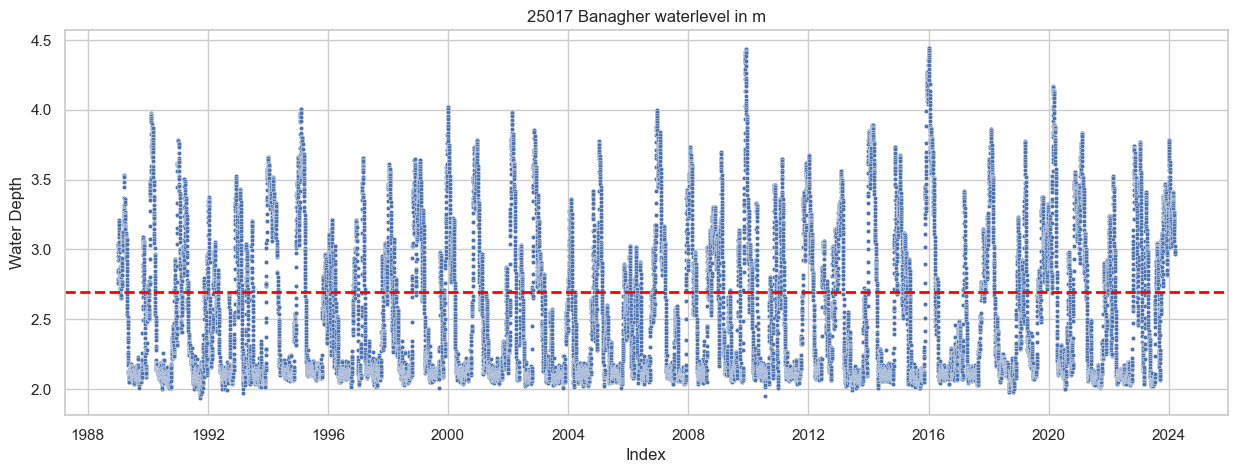

In [41]:
df_one_point = df.iloc[::48] # every 24th point to keep it simpler for this plot

#sns.set(style="whitegrid")
plt.figure(figsize=(15, 5))
sns.scatterplot(data=df_one_point, x=df_one_point.index, y='Value', s=10, palette=colour_pal)

plt.axhline(y=field_flood, color='red', linestyle='--', linewidth=2) # mark this name
# add quartile lines
plt.title('25017 Banagher waterlevel in m')
plt.xlabel('Index')
plt.ylabel('Water Depth')

# Show the plot
plt.show()

# this was the older plot
#df.plot(style='.', 
#        figsize=(15,5), 
#        color=colour_pal[0], 
#        title='25017 Banagher waterlevel in m',
#        markersize=1)
#plt.show()



#### Drop Outliers

In [23]:
def find_outliers(series, scale=3, quantiles=(0.25, 0.75)):
    
    Q1, Q3 = series.quantile(quantiles)

    IQR = Q3 - Q1
    lower_bound = Q1 - scale * IQR
    upper_bound = Q3 + scale * IQR

    return (lower_bound, upper_bound)

def describe_outliers(df_daily, scale=1.5, quantiles=(0.25, 0.75)):
 
    outlier_summary = {}

    for column in df_daily.columns:
        series = df_daily[column]

        (lower_bound, upper_bound) = find_outliers(series, scale, quantiles)

        # Identify and count outliers
        outliers = series[(series < lower_bound) | (series > upper_bound)]
        outlier_summary[column] = len(outliers)

    return outlier_summary

describe_outliers(df_daily) # to do all the columns at the same time


#df.index

{'Day Min': 181, 'Day Mean': 181, 'Day Max': 178}

In [24]:
def drop_outliers(df_daily, scale=1.5, quantiles=(0.25, 0.75)):
    #cleaned_df = df_daily.copy()  # Create a copy of the original DataFrame

    for column in df_daily.columns:
        series = df_daily[column]
        (lower_bound, upper_bound) = find_outliers(series, scale, quantiles)

        # Drop outliers
        outliers_index = (series < lower_bound) | (series > upper_bound)
        df_daily = df_daily[~outliers_index]

    return df_daily

df_daily = drop_outliers(df_daily)


describe_outliers(df_daily) # now check outliers again

{'Day Min': 0, 'Day Mean': 0, 'Day Max': 0}

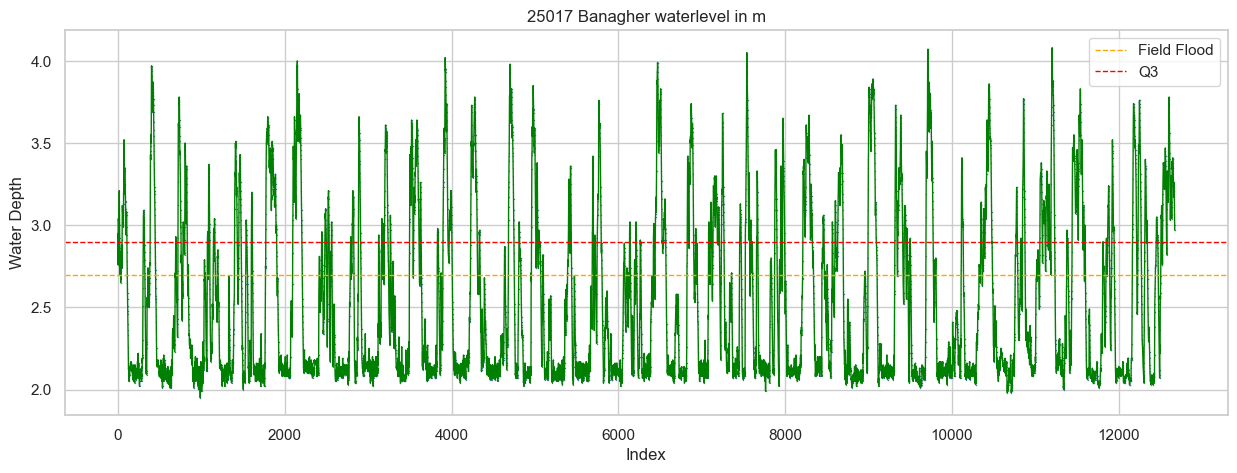

In [44]:
# plot daily values now that I have dropped the outliers

#df2.plot(style='.', 
#        figsize=(15,5), 
#        color=colour_pal[1], 
#        title='waterlevel in m, Dailies',
#        markersize=1)
#plt.show()

plt.figure(figsize=(15, 5))

# Resetting index to integers for plotting
#df_daily.reset_index(inplace=True)

sns.scatterplot(data=df_daily, x=df_daily.index, y='Day Mean', s=1)
plt.plot(df_daily.index, df_daily['Day Mean'], color='green', linewidth=1)

plt.axhline(y=field_flood, color='orange', linestyle='--', linewidth=1, label='Field Flood')

# Calculate quartiles
Q1 = df_daily['Day Mean'].quantile(0.25)
Q3 = df_daily['Day Mean'].quantile(0.75)

# Add quartile lines
#plt.axhline(y=Q1, color='blue', linestyle='--', linewidth=1, label='Q1')
plt.axhline(y=Q3, color='red', linestyle='--', linewidth=1, label='Q3')


plt.title('25017 Banagher waterlevel in m')
plt.xlabel('Index')
plt.ylabel('Water Depth')
plt.legend()
plt.show()


## Train / Test Split

In [12]:
# later I will change this to full cross validation
#https://machinelearningmastery.com/xgboost-for-regression/
#I should be able to replace with this
'''This entire section is probably redundant as I can use cross validation instead of splitting into train/test.'''

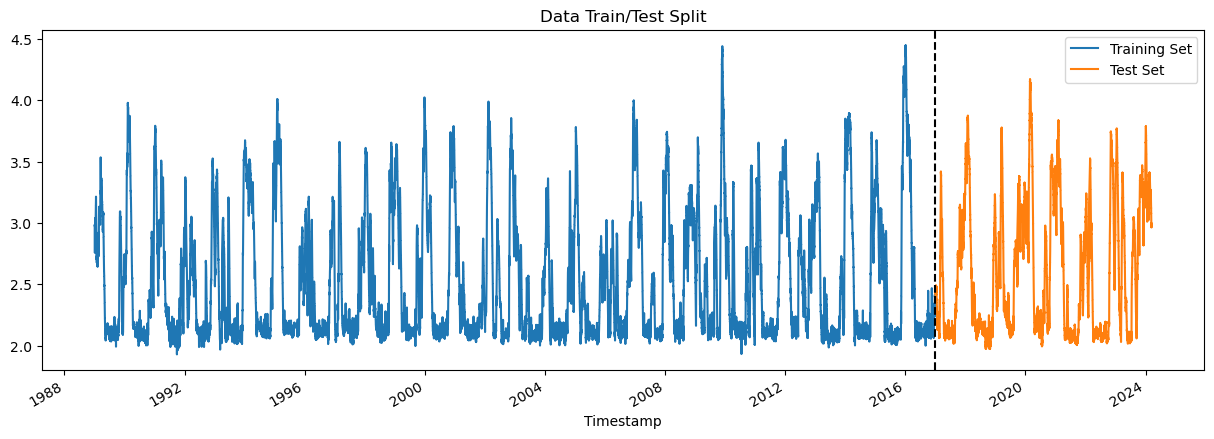

In [13]:
train = df.loc[df.index < '01-01-2017']
test = df.loc[df.index >= '01-01-2017']

fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')

ax.axvline('01-01-2017', color='black', ls='--')
ax.legend(['Training Set', 'Test Set'])
plt.show()


In [47]:
df_daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12672 entries, 0 to 12671
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   level_0   12672 non-null  int64         
 1   index     12672 non-null  int64         
 2   Day       12672 non-null  datetime64[ns]
 3   Day Min   12672 non-null  float64       
 4   Day Mean  12672 non-null  float64       
 5   Day Max   12672 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(2)
memory usage: 594.1 KB


In [45]:
# weekly plot, or monthly - March 2024
df_daily.loc[(df_daily.index > '01-03-2024') & (df_daily.index <= '31-03-2024')].plot(title='Month of Data') 
plt.show()

# the weekly seems trivial, but the monthly is relevant with the daily data.
# maybe I will revisit this and put in a number of months where we want some detail.
# quarterly here might actually be better, for the months where there is risk of flood water.

TypeError: Invalid comparison between dtype=int64 and str

### Feature Creation

In [15]:
df.index

DatetimeIndex(['1989-01-02 09:00:00+00:00', '1989-01-02 09:15:00+00:00',
               '1989-01-02 09:30:00+00:00', '1989-01-02 09:45:00+00:00',
               '1989-01-02 10:00:00+00:00', '1989-01-02 10:15:00+00:00',
               '1989-01-02 10:30:00+00:00', '1989-01-02 10:45:00+00:00',
               '1989-01-02 11:00:00+00:00', '1989-01-02 11:15:00+00:00',
               ...
               '2024-03-13 22:15:00+00:00', '2024-03-13 22:30:00+00:00',
               '2024-03-13 22:45:00+00:00', '2024-03-13 23:00:00+00:00',
               '2024-03-13 23:15:00+00:00', '2024-03-13 23:30:00+00:00',
               '2024-03-13 23:45:00+00:00', '2024-03-14 00:00:00+00:00',
               '2024-03-14 00:15:00+00:00', '2024-03-14 00:30:00+00:00'],
              dtype='datetime64[ns, UTC]', name='Timestamp', length=1218710, freq=None)

In [16]:
df2.index

DatetimeIndex(['1989-01-02', '1989-01-03', '1989-01-04', '1989-01-05',
               '1989-01-06', '1989-01-07', '1989-01-08', '1989-01-09',
               '1989-01-10', '1989-01-11',
               ...
               '2024-03-04', '2024-03-05', '2024-03-06', '2024-03-07',
               '2024-03-08', '2024-03-09', '2024-03-10', '2024-03-11',
               '2024-03-12', '2024-03-13'],
              dtype='datetime64[ns]', name='Day', length=12855, freq=None)

In [17]:
def create_features(df):
    '''
    Create time series features based on time series index.
    '''
    df = df.copy()
    df['hour'] = df.index.hour # trivial for waterlevels
    df['dayofweek'] = df.index.day_of_week # trivial for waterlevels
    df['quarter'] = df.index.quarter # not interesting for waterlevels
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df = create_features(df)

def create_features_simple(df):
    '''
    Create time series features based on time series index.
    The function that looks at the average daily values can be used for year on year comparison
    '''    
    df['dayofweek'] = df.index.day_of_week # trivial for waterlevels
    df['quarter'] = df.index.quarter # not interesting for waterlevels
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df2 = create_features_simple(df2)

In [18]:
df.tail(10)

,#Timestamp,Value,hour,dayofweek,quarter,month,year,dayofyear
Timestamp,,,,,,,,
2024-03-13 22:15:00+00:00,2024-03-13T22:15:00.000Z,2.990,22,2,1,3,2024,73
2024-03-13 22:30:00+00:00,2024-03-13T22:30:00.000Z,2.991,22,2,1,3,2024,73
2024-03-13 22:45:00+00:00,2024-03-13T22:45:00.000Z,2.991,22,2,1,3,2024,73
2024-03-13 23:00:00+00:00,2024-03-13T23:00:00.000Z,2.991,23,2,1,3,2024,73
2024-03-13 23:15:00+00:00,2024-03-13T23:15:00.000Z,2.993,23,2,1,3,2024,73
2024-03-13 23:30:00+00:00,2024-03-13T23:30:00.000Z,2.994,23,2,1,3,2024,73
2024-03-13 23:45:00+00:00,2024-03-13T23:45:00.000Z,2.994,23,2,1,3,2024,73
2024-03-14 00:00:00+00:00,2024-03-14T00:00:00.000Z,2.995,0,3,1,3,2024,74
2024-03-14 00:15:00+00:00,2024-03-14T00:15:00.000Z,2.996,0,3,1,3,2024,74


In [19]:
df2.tail(10)

,Day Min,Day Mean,Day Max,dayofweek,quarter,month,year,dayofyear
Day,,,,,,,,
2024-03-04,3.207,3.23,3.251,0,1,3,2024,64
2024-03-05,3.180,3.20,3.217,1,1,3,2024,65
2024-03-06,3.204,3.21,3.221,2,1,3,2024,66
2024-03-07,3.178,3.19,3.206,3,1,3,2024,67
2024-03-08,3.140,3.16,3.180,4,1,3,2024,68
2024-03-09,3.092,3.12,3.141,5,1,3,2024,69
2024-03-10,3.035,3.07,3.093,6,1,3,2024,70
2024-03-11,2.977,3.00,3.035,0,1,3,2024,71
2024-03-12,2.967,2.97,2.978,1,1,3,2024,72


### Visualise our feature / target relationship

Text(0.5, 1.0, 'Waterlevel in M')

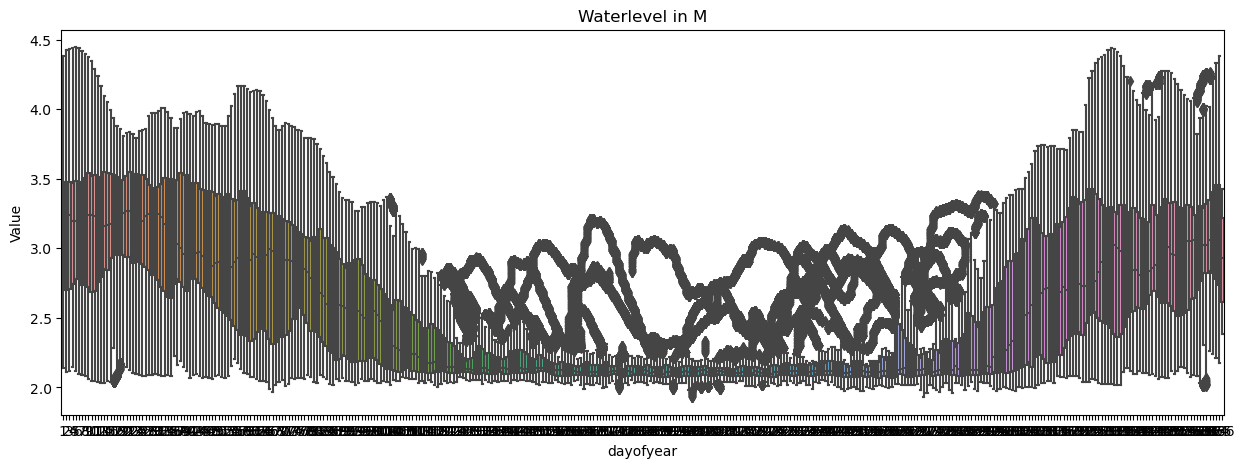

In [20]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='dayofyear', y='Value') #whis=(1, 99)
ax.set_title('Waterlevel in M')
# this example here is too detailed, maybe I need to calculate a weekly average from the average of the daily averages.
# another trivial example here if I explore the other dataset.

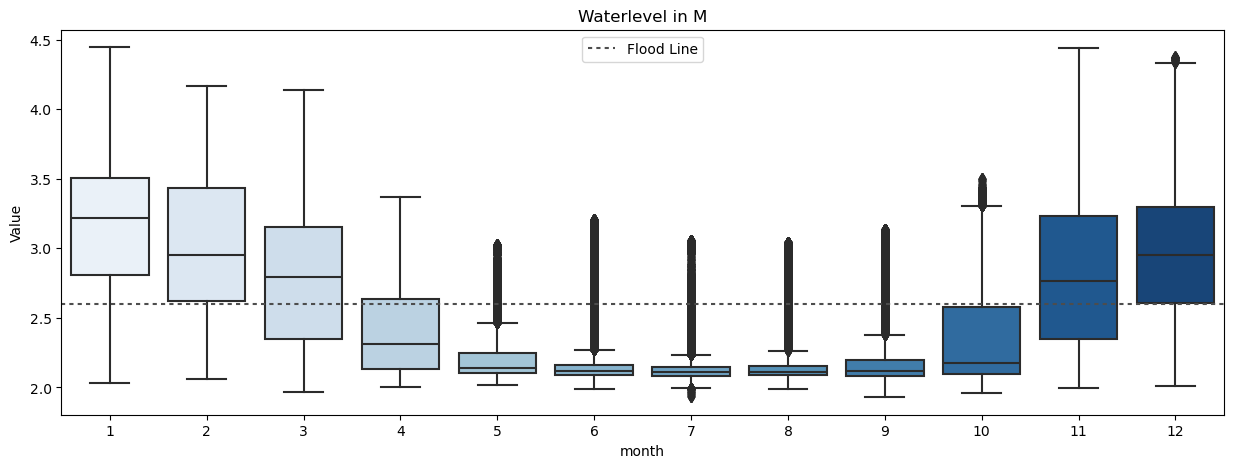

In [21]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='month', y='Value', palette='Blues') # not sure if the whiskers and outliers ok. whis=(2, 98)
ax.set_title('Waterlevel in M')
# I should put in the floodline here, for average projection of flooding in the future
# this is an absolute guess for first order approximation.
ax.axhline(2.6, color=".3", dashes=(2, 2), label='Flood Line')
plt.legend()
plt.show()

There is more scope for plots here, insert lines for percentiles, day of the year trends, quarterly and monthly year on year comparison looking for waterlevels websites definition for what is in flood and our estimation for flood levels in the field.

I am starting with the 5 number summary, and I can add in those as lines in a second plot.

In [22]:
# should I count the numbers of outliers in the summer months? This box plot and the one above seem to show them, is that enough for me?

In [23]:
# calculate and print the 5 number summaries
'''
quartiles = np.percentile(df['Value'], [25, 50, 75])
data_min, data_max = df['Value'].min(), df['Value'].max()

# print 5-number summary
print('Min: %.3f' % data_min)
print('Q1: %.3f' % quartiles[0])
print('Median: %.3f' % quartiles[1])
print('Q3: %.3f' % quartiles[2])
print('Max: %.3f' % data_max)
'''

#def summary(data): # more concise
#    '''Seven-number summary, printing the results'''

##    return np.percentile(data, [0, 10, 25, 50, 75, 90, 100], method="midpoint")
#print([0, 10, 25, 50, 75, 90, 100])
#print(summary(df['Value']))

[0, 10, 25, 50, 75, 90, 100]
[1.93  2.08  2.113 2.289 2.907 3.372 4.446]


In [24]:
# How do these compare to the ones on the Waterlevels website?

### My Chosen Model / Models
##### Regression model

In [25]:
train = create_features(train)
test = create_features(test)

FEATURES = ['hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear']
TARGET = ['Value']

X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

# https://machinelearningmastery.com/tune-learning-rate-for-gradient-boosting-with-xgboost-in-python/
# I might edit this further, its KFOLD mixed in with SearchGrid, so I can check a number of hyperparameters.
# I am not sure how much time I should spend on the hyperparameters, I will plot some predicted points first and make the call.
# I can then exclude the test/train split, and the above notes on CV.


In [26]:
reg = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=50) # is this accurate enough in this case?
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=25)

[0]	validation_0-rmse:1.47761	validation_1-rmse:1.55768
[25]	validation_0-rmse:0.14186	validation_1-rmse:0.63322
[50]	validation_0-rmse:0.09427	validation_1-rmse:0.63714
[57]	validation_0-rmse:0.08549	validation_1-rmse:0.63803


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=1000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

I suspect there is overfitting here, so I will try again.

In [27]:
reg = xgb.XGBRegressor(n_estimators=3000, 
                       early_stopping_rounds=50,
                       learning_rate=0.005) # Regularization
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=100)

[0]	validation_0-rmse:2.07732	validation_1-rmse:2.17135
[100]	validation_0-rmse:1.28012	validation_1-rmse:1.37040
[200]	validation_0-rmse:0.80498	validation_1-rmse:0.93854
[300]	validation_0-rmse:0.52674	validation_1-rmse:0.72806
[400]	validation_0-rmse:0.37168	validation_1-rmse:0.64330
[500]	validation_0-rmse:0.28924	validation_1-rmse:0.61498
[600]	validation_0-rmse:0.24587	validation_1-rmse:0.60951
[655]	validation_0-rmse:0.22973	validation_1-rmse:0.60947


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.005, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=3000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [28]:
# I'm going to try gridsearch to get the best hyperparameters.

In [ ]:
reg_cv = GridSearchCV(reg, {'max_depth': [3,4,6], 'n_estimators': [500,1000,2000,3000]}, verbose=100)

reg_cv.fit(X_train,y_train, eval_set=[(X_train, y_train), (X_test, y_test)]) # put the verbose here instead

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV 1/5; 1/12] START max_depth=3, n_estimators=500..............................
[0]	validation_0-rmse:2.07739	validation_1-rmse:2.17180
[1]	validation_0-rmse:2.06731	validation_1-rmse:2.16171
[2]	validation_0-rmse:2.05728	validation_1-rmse:2.15168
[3]	validation_0-rmse:2.04730	validation_1-rmse:2.14170
[4]	validation_0-rmse:2.03738	validation_1-rmse:2.13176
[5]	validation_0-rmse:2.02750	validation_1-rmse:2.12189
[6]	validation_0-rmse:2.01768	validation_1-rmse:2.11206
[7]	validation_0-rmse:2.00791	validation_1-rmse:2.10229
[8]	validation_0-rmse:1.99818	validation_1-rmse:2.09257
[9]	validation_0-rmse:1.98851	validation_1-rmse:2.08290
[10]	validation_0-rmse:1.97889	validation_1-rmse:2.07329
[11]	validation_0-rmse:1.96931	validation_1-rmse:2.06372
[12]	validation_0-rmse:1.95979	validation_1-rmse:2.05420
[13]	validation_0-rmse:1.95031	validation_1-rmse:2.04474
[14]	validation_0-rmse:1.94089	validation_1-rmse:2.03533
[15]	validati

In [ ]:
reg_cv.best_params_

In [ ]:
gbm = xgb.XGBRegressor(**reg_cv.best_params_) # theres no learning rate, should I use gridsearch and try and include them?

gbm.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=20)

In [ ]:
predictions = gbm.predict(X_test)
predictions.shape # predicted water levels, but for how long?
predictions

#### Evaluate Scores

In [ ]:
gbm.score(X_train,y_train)

In [ ]:
gbm.score(X_test,y_test) # potential issues here.
# should I try to get early stopping and the other hyperparameters back in?
# maybe I should continue first with predictions based on the performance I managed first

Here are a few scenarios where you might observe a negative R^2 score:

Model is performing very poorly: The model might not be capturing any of the variance in the target variable or might be capturing it in the wrong direction. In such cases, the model is worse than a horizontal line (mean prediction), resulting in a negative R^2 score.

Data preprocessing issues: Negative R^2 scores can sometimes indicate problems with data preprocessing. For instance, if there's a mismatch between the features and the target variable, or if the target variable is transformed in a way that makes it hard for the model to learn patterns, it could result in negative scores.

Random chance: In some rare cases, particularly with very small datasets, a negative R^2 score might occur due to random chance.

If you encounter a negative R^2 score, it's crucial to investigate why this might be happening. It could be indicative of underlying issues with the model, the data, or the modeling process itself. In such cases, it's often helpful to revisit the data preprocessing steps, the model architecture, and consider if additional features or more data could improve model performance. Additionally, cross-validation or further evaluation metrics can provide more insights into the model's performance.

In [ ]:
# need to add in the predicted points here for a few months and see what it looks like.

### Feature Importances

In [ ]:
# this is not really interesting but worth looking at briefly.
fi = pd.DataFrame(data=reg.feature_importances_,
                  index=reg.feature_names_in_,
                  columns=['importance'])

fi.sort_values('importance').plot(kind='barh', title='Feature Importance')
plt.show()    

This is showing that breaking down the first dataset into hour or day of the week is trivial. Using the day of the year, and similarly its quater and months can be handy. The year is also important, and I will investigate by looking at the flood windows by year on year.